# setup

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings, time
warnings.filterwarnings('ignore')

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, recall_score, precision_score, roc_curve, precision_recall_curve,
                            confusion_matrix, ConfusionMatrixDisplay, classification_report)

try:
    import lightgbm as lgb
except ImportError:
    raise SystemExit("Run: pip install lightgbm")
sns.set_style("whitegrid"); RANDOM_STATE = 42

# Load Dataset

In [3]:
df = pd.read_csv('train(1).csv')
feats = [c for c in df.columns if c not in ("ID_code", "target")]
print("Shape:", df.shape, "| features:", len(feats))
df

Shape: (200000, 202) | features: 200


,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199995,train_199995,0,11.4880,-0.4956,8.2622,3.5142,10.3404,11.6081,5.6709,15.1516,...,6.1415,13.2305,3.9901,0.9388,18.0249,-1.7939,2.1661,8.5326,16.6660,-17.8661
199996,train_199996,0,4.9149,-2.4484,16.7052,6.6345,8.3096,-10.5628,5.8802,21.5940,...,4.9611,4.6549,0.6998,1.8341,22.2717,1.7337,-2.1651,6.7419,15.9054,0.3388
199997,train_199997,0,11.2232,-5.0518,10.5127,5.6456,9.3410,-5.4086,4.5555,21.5571,...,4.0651,5.4414,3.1032,4.8793,23.5311,-1.5736,1.2832,8.7155,13.8329,4.1995
199998,train_199998,0,9.7148,-8.6098,13.6104,5.7930,12.5173,0.5339,6.0479,17.0152,...,2.6840,8.6587,2.7337,11.1178,20.4158,-0.0786,6.7980,10.0342,15.5289,-13.9001


In [4]:
df.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


In [5]:
df.tail()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
199995,train_199995,0,11.4880,-0.4956,8.2622,3.5142,10.3404,11.6081,5.6709,15.1516,...,6.1415,13.2305,3.9901,0.9388,18.0249,-1.7939,2.1661,8.5326,16.6660,-17.8661
199996,train_199996,0,4.9149,-2.4484,16.7052,6.6345,8.3096,-10.5628,5.8802,21.5940,...,4.9611,4.6549,0.6998,1.8341,22.2717,1.7337,-2.1651,6.7419,15.9054,0.3388
199997,train_199997,0,11.2232,-5.0518,10.5127,5.6456,9.3410,-5.4086,4.5555,21.5571,...,4.0651,5.4414,3.1032,4.8793,23.5311,-1.5736,1.2832,8.7155,13.8329,4.1995
199998,train_199998,0,9.7148,-8.6098,13.6104,5.7930,12.5173,0.5339,6.0479,17.0152,...,2.6840,8.6587,2.7337,11.1178,20.4158,-0.0786,6.7980,10.0342,15.5289,-13.9001
199999,train_199999,0,10.8762,-5.7105,12.1183,8.0328,11.5577,0.3488,5.2839,15.2058,...,8.9842,1.6893,0.1276,0.3766,15.2101,-2.4907,-2.2342,8.1857,12.1284,0.1385


In [6]:
df.shape

(200000, 202)

In [7]:
df.describe()

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,...,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,0.100490,10.679914,-1.627622,10.715192,6.796529,11.078333,-5.065317,5.408949,16.545850,0.284162,...,3.234440,7.438408,1.927839,3.331774,17.993784,-0.142088,2.303335,8.908158,15.870720,-3.326537
std,0.300653,3.040051,4.050044,2.640894,2.043319,1.623150,7.863267,0.866607,3.418076,3.332634,...,4.559922,3.023272,1.478423,3.992030,3.135162,1.429372,5.454369,0.921625,3.010945,10.438015
min,0.000000,0.408400,-15.043400,2.117100,-0.040200,5.074800,-32.562600,2.347300,5.349700,-10.505500,...,-14.093300,-2.691700,-3.814500,-11.783400,8.694400,-5.261000,-14.209600,5.960600,6.299300,-38.852800
25%,0.000000,8.453850,-4.740025,8.722475,5.254075,9.883175,-11.200350,4.767700,13.943800,-2.317800,...,-0.058825,5.157400,0.889775,0.584600,15.629800,-1.170700,-1.946925,8.252800,13.829700,-11.208475
50%,0.000000,10.524750,-1.608050,10.580000,6.825000,11.108250,-4.833150,5.385100,16.456800,0.393700,...,3.203600,7.347750,1.901300,3.396350,17.957950,-0.172700,2.408900,8.888200,15.934050,-2.819550
75%,0.000000,12.758200,1.358625,12.516700,8.324100,12.261125,0.924800,6.003000,19.102900,2.937900,...,6.406200,9.512525,2.949500,6.205800,20.396525,0.829600,6.556725,9.593300,18.064725,4.836800
max,1.000000,20.315000,10.376800,19.353000,13.188300,16.671400,17.251600,8.447700,27.691800,10.151300,...,18.440900,16.716500,8.402400,18.281800,27.928800,4.272900,18.321500,12.000400,26.079100,28.500700


In [8]:
df.columns

Index(['ID_code', 'target', 'var_0', 'var_1', 'var_2', 'var_3', 'var_4',
       'var_5', 'var_6', 'var_7',
       ...
       'var_190', 'var_191', 'var_192', 'var_193', 'var_194', 'var_195',
       'var_196', 'var_197', 'var_198', 'var_199'],
      dtype='str', length=202)

# Data analysis report
* The features are anonymized (var_0 ... var_199), so business-driven EDA is not possible. Per the brief, the analysis is statistical: data quality, target balance, distributions, feature-target signal and feature-feature dependence.

## Data quality

In [9]:
print("Missing values      :", int(df.isnull().sum().sum()))
print("Duplicate rows      :", int(df.duplicated().sum()))
print("Unique ID_code      :", df["ID_code"].is_unique)
print("Dtypes              :", df[feats].dtypes.value_counts().to_dict())

Missing values      : 0
Duplicate rows      : 0
Unique ID_code      : True
Dtypes              : {dtype('float64'): 200}


##  Target distribution

         count  percent
target                 
0       179902    89.95
1        20098    10.05


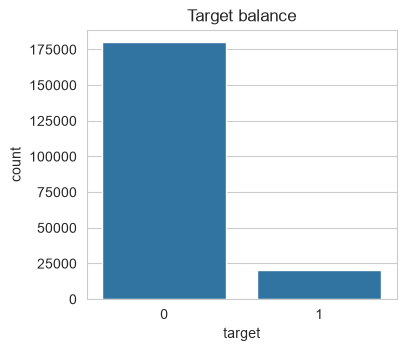

In [10]:
vc = df["target"].value_counts()
print(pd.DataFrame({"count": vc, "percent": (vc / len(df) * 100).round(2)}))
fig, ax = plt.subplots(figsize=(4, 3.5))
sns.countplot(x="target", data=df, ax=ax); ax.set_title("Target balance"); plt.show()

## Descriptive statistics, skew and cardinality

In [11]:
desc = df[feats].describe().T
desc["skew"] = df[feats].skew(); desc["kurtosis"] = df[feats].kurt()
desc["n_unique"] = df[feats].nunique()
display(desc.head(10))
print("Mean |skew| across features:", round(desc["skew"].abs().mean(), 3))
print("Cardinality range          :", desc["n_unique"].min(), "-", desc["n_unique"].max())

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,n_unique
var_0,200000.0,10.679914,3.040051,0.4084,8.453850,10.52475,12.758200,20.3150,0.235639,-0.273593,94672
var_1,200000.0,-1.627622,4.050044,-15.0434,-4.740025,-1.60805,1.358625,10.3768,0.053115,-0.607265,108932
var_2,200000.0,10.715192,2.640894,2.1171,8.722475,10.58000,12.516700,19.3530,0.260313,-0.336616,86555
var_3,200000.0,6.796529,2.043319,-0.0402,5.254075,6.82500,8.324100,13.1883,-0.003548,-0.602623,74597
var_4,200000.0,11.078333,1.623150,5.0748,9.883175,11.10825,12.261125,16.6714,-0.048210,-0.534993,63515
var_5,200000.0,-5.065317,7.863267,-32.5626,-11.200350,-4.83315,0.924800,17.2516,-0.002038,-0.668954,141029
var_6,200000.0,5.408949,0.866607,2.3473,4.767700,5.38510,6.003000,8.4477,0.149476,-0.383997,38599
var_7,200000.0,16.545850,3.418076,5.3497,13.943800,16.45680,19.102900,27.6918,0.084598,-0.671014,103063
var_8,200000.0,0.284162,3.332634,-10.5055,-2.317800,0.39370,2.937900,10.1513,-0.104643,-0.803599,98617
var_9,200000.0,7.567236,1.235070,3.9705,6.618800,7.62960,8.584425,11.1506,-0.175433,-0.760764,49417


Mean |skew| across features: 0.084
Cardinality range          : 451 - 169968


## Outliers (IQR rule)

var_179    0.75
var_44     0.60
var_93     0.44
var_146    0.40
var_192    0.37
var_31     0.32
var_133    0.29
var_105    0.29
var_38     0.25
var_124    0.25
dtype: float64


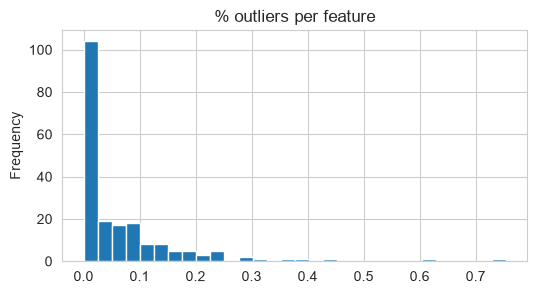

In [12]:
q1, q3 = df[feats].quantile(.25), df[feats].quantile(.75); iqr = q3 - q1
out_pct = (((df[feats] < q1 - 1.5*iqr) | (df[feats] > q3 + 1.5*iqr)).mean() * 100).sort_values(ascending=False)
print(out_pct.head(10).round(2))
out_pct.plot(kind="hist", bins=30, figsize=(6, 3), title="% outliers per feature"); plt.show()

## Feature vs target signal

var_81    -0.0809
var_139   -0.0741
var_12    -0.0695
var_6      0.0667
var_110    0.0643
var_146   -0.0636
var_53     0.0634
var_26     0.0624
var_76    -0.0619
var_174   -0.0617
dtype: float64


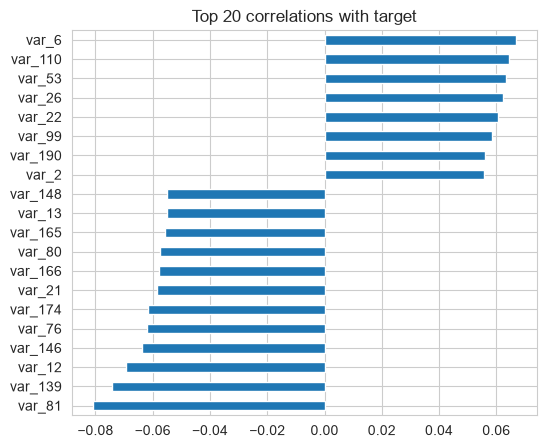

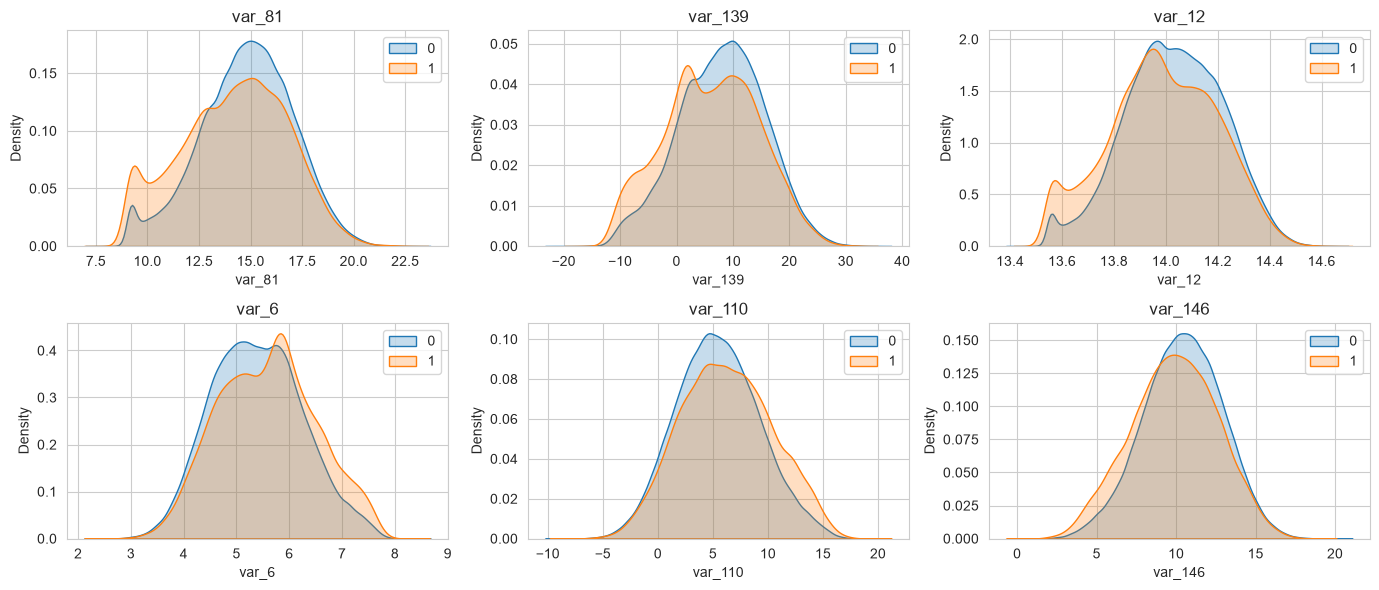

In [13]:
corr_t = df[feats].corrwith(df["target"]).sort_values(key=abs, ascending=False)
print(corr_t.head(10).round(4))
corr_t.head(20).sort_values().plot(kind="barh", figsize=(6, 5), title="Top 20 correlations with target"); plt.show()
top6 = corr_t.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, c in zip(axes.ravel(), top6):
    sns.kdeplot(df.loc[df.target == 0, c], ax=ax, label="0", fill=True)
    sns.kdeplot(df.loc[df.target == 1, c], ax=ax, label="1", fill=True)
    ax.set_title(c); ax.legend()
plt.tight_layout(); plt.show()

## Feature-feature dependence

In [14]:
cm = df[feats].corr().abs().to_numpy(copy=True); np.fill_diagonal(cm, 0)
print("Max absolute correlation between two features:", round(cm.max(), 4))
print("Pairs with |r| > 0.1:", int((cm > 0.1).sum() // 2))

Max absolute correlation between two features: 0.0098
Pairs with |r| > 0.1: 0


# Preprocessing and split

* Stratified 70% train / 15% validation / 15% test. Validation is used for model selection and early stopping, test is touched once at the end.

In [15]:
X, y = df[feats], df["target"]
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=RANDOM_STATE)
print(X_train.shape, X_val.shape, X_test.shape)
print("Positive rate train/val/test:", round(y_train.mean(), 4), round(y_val.mean(), 4), round(y_test.mean(), 4))

(140000, 200) (30000, 200) (30000, 200)
Positive rate train/val/test: 0.1005 0.1005 0.1005


# Predictive models

* Baselines handle imbalance with class_weight='balanced'. Scaling is applied inside pipelines so no information leaks from validation data.

In [16]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Gaussian Naive Bayes": GaussianNB(),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=20, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "LightGBM": lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.05, num_leaves=8, min_child_samples=80,
                                   colsample_bytree=0.1, subsample=0.4, subsample_freq=5, reg_alpha=5, reg_lambda=5,
                                   random_state=RANDOM_STATE, verbose=-1),
}
rows, val_proba = [], {}
for name, m in models.items():
    t0 = time.time()
    if name == "LightGBM":
        m.fit(X_train, y_train, eval_set=[(X_val, y_val)], eval_metric="auc",
              callbacks=[lgb.early_stopping(200, verbose=False)])
    else:
        m.fit(X_train, y_train)
    p = m.predict_proba(X_val)[:, 1]; val_proba[name] = p; pred = (p >= 0.5).astype(int)
    rows.append({"Model": name, "ROC-AUC": roc_auc_score(y_val, p), "PR-AUC": average_precision_score(y_val, p),
                 "F1@0.5": f1_score(y_val, pred), "Recall@0.5": recall_score(y_val, pred),
                 "Precision@0.5": precision_score(y_val, pred, zero_division=0), "Fit time (s)": round(time.time() - t0, 1)})
    print("done:", name)

done: Logistic Regression
done: Gaussian Naive Bayes
done: Random Forest
done: LightGBM


#  Model comparison report

,Model,ROC-AUC,PR-AUC,F1@0.5,Recall@0.5,Precision@0.5,Fit time (s)
0,LightGBM,0.8959,0.5925,0.4420,0.3148,0.7420,13.900000
1,Gaussian Naive Bayes,0.8861,0.5723,0.4553,0.3373,0.7004,0.600000
2,Logistic Regression,0.8566,0.5000,0.4165,0.7721,0.2852,1.000000
3,Random Forest,0.8201,0.4049,0.3759,0.3078,0.4828,39.000000


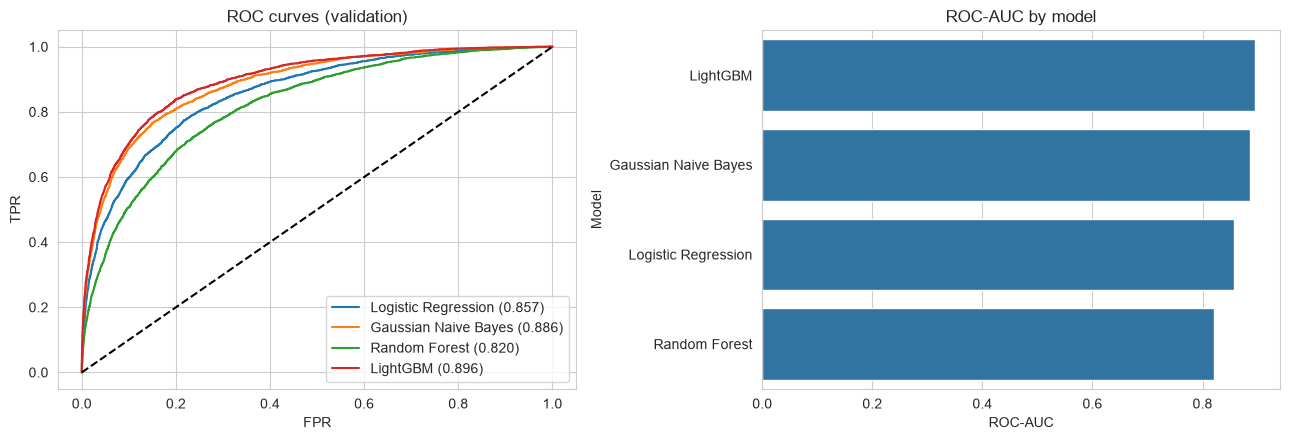

In [17]:
cmp = pd.DataFrame(rows).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(cmp.style.format({c: "{:.4f}" for c in ["ROC-AUC", "PR-AUC", "F1@0.5", "Recall@0.5", "Precision@0.5"]})
        .background_gradient(subset=["ROC-AUC", "PR-AUC"], cmap="Greens"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, p in val_proba.items():
    fpr, tpr, _ = roc_curve(y_val, p); ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_val, p):.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set(title="ROC curves (validation)", xlabel="FPR", ylabel="TPR"); ax[0].legend()
sns.barplot(data=cmp, x="ROC-AUC", y="Model", ax=ax[1]); ax[1].set_title("ROC-AUC by model")
plt.tight_layout(); plt.show()

How to read this table: the model with the highest ROC-AUC and PR-AUC that also trains in reasonable time is recommended. Weak per-feature signal usually favours Naive Bayes and boosted trees with strong regularisation over deep or unregularised trees; the table above is the evidence for the final choice.

# Final model, threshold and feature importance

Selected model: LightGBM
F1-optimal threshold (from validation): 0.2647
TEST ROC-AUC: 0.8959 | PR-AUC: 0.6046
              precision    recall  f1-score   support

           0     0.9512    0.9469    0.9490     26986
           1     0.5429    0.5647    0.5536      3014

    accuracy                         0.9085     30000
   macro avg     0.7470    0.7558    0.7513     30000
weighted avg     0.9101    0.9085    0.9093     30000



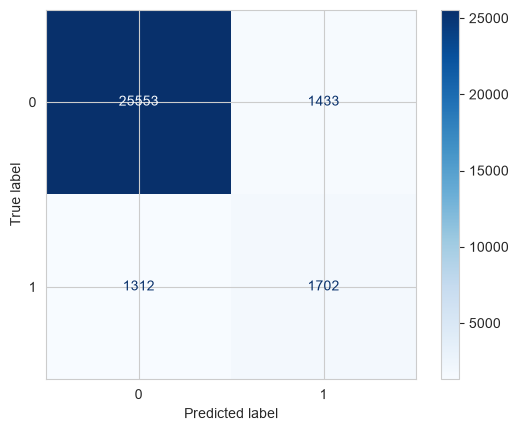

In [18]:
best_name = cmp.loc[0, "Model"]; best = models[best_name]
print("Selected model:", best_name)
p_val = best.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, p_val)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
threshold = thr[f1s.argmax()]; print("F1-optimal threshold (from validation):", round(float(threshold), 4))

p_test = best.predict_proba(X_test)[:, 1]; pred_test = (p_test >= threshold).astype(int)
print("TEST ROC-AUC:", round(roc_auc_score(y_test, p_test), 4), "| PR-AUC:", round(average_precision_score(y_test, p_test), 4))
print(classification_report(y_test, pred_test, digits=4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test)).plot(cmap="Blues"); plt.show()

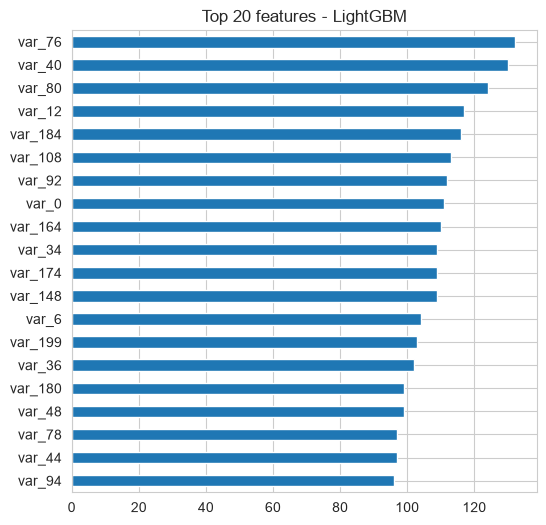

Saved best_model.pkl


In [19]:
import joblib

if hasattr(best, "feature_importances_"):
    imp = pd.Series(best.feature_importances_, index=feats).sort_values(ascending=False).head(20)
    imp.sort_values().plot(kind="barh", figsize=(6, 6), title=f"Top 20 features - {best_name}"); plt.show()
else:
    print("Feature importance plot not available for", best_name)
joblib.dump({"model": best, "threshold": float(threshold), "features": feats}, "best_model.pkl")
print("Saved best_model.pkl")

In [20]:
# Optional: score the unlabeled test.csv for submission
import os
if os.path.exists("test.csv"):
    t = pd.read_csv("test.csv")
    sub = pd.DataFrame({"ID_code": t["ID_code"], "target": best.predict_proba(t[feats])[:, 1]})
    sub.to_csv("submission.csv", index=False); print(sub.head())

In [21]:
import sweetviz as sv
my_report = sv.analyze(df, pairwise_analysis='off')## pass the original dataframe
my_report.show_html('SWEETVIZ_REPORT.html') # Default arguments will generate to "SWEETVIZ_REPORT.html"

                                             |          | [  0%]   00:00 -> (? left)

findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight nor

Report SWEETVIZ_REPORT.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.
